In [2]:
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
import pickle
from transformers import BertTokenizer, TFBertModel
import numpy as np
import tensorflow as tf

In [ ]:
def preprocess_text(text):
    text = re.sub(r'\s+', ' ', text) 
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text) 
    text = text.lower() 
    return text

In [ ]:
file_path = "10k_LLM_complaints_unique.csv"  
data = pd.read_csv(file_path, encoding='ISO-8859-1')

In [5]:
data['feedback'] = data['feedback'].apply(preprocess_text)

In [6]:
X = data['feedback']
y = data['category']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
tfidf_vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

In [8]:
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

In [9]:
for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    print(f"\nClassification Report for {model_name}:\n")
    print(classification_report(y_test, y_pred))

Training Logistic Regression...

Classification Report for Logistic Regression:

                        precision    recall  f1-score   support

        administration       0.98      0.95      0.96       206
             admission       0.98      0.95      0.97       198
               canteen       1.00      0.98      0.99       195
                  exam       0.99      0.99      0.99       213
               finance       0.94      0.97      0.95       223
                hostel       0.99      0.99      0.99       185
               library       1.00      0.98      0.99       204
                sports       0.94      0.98      0.96       171
training and placement       0.98      1.00      0.99       201
             transport       0.96      0.97      0.96       194

              accuracy                           0.98      1990
             macro avg       0.98      0.98      0.98      1990
          weighted avg       0.98      0.98      0.98      1990

Training Support Vec

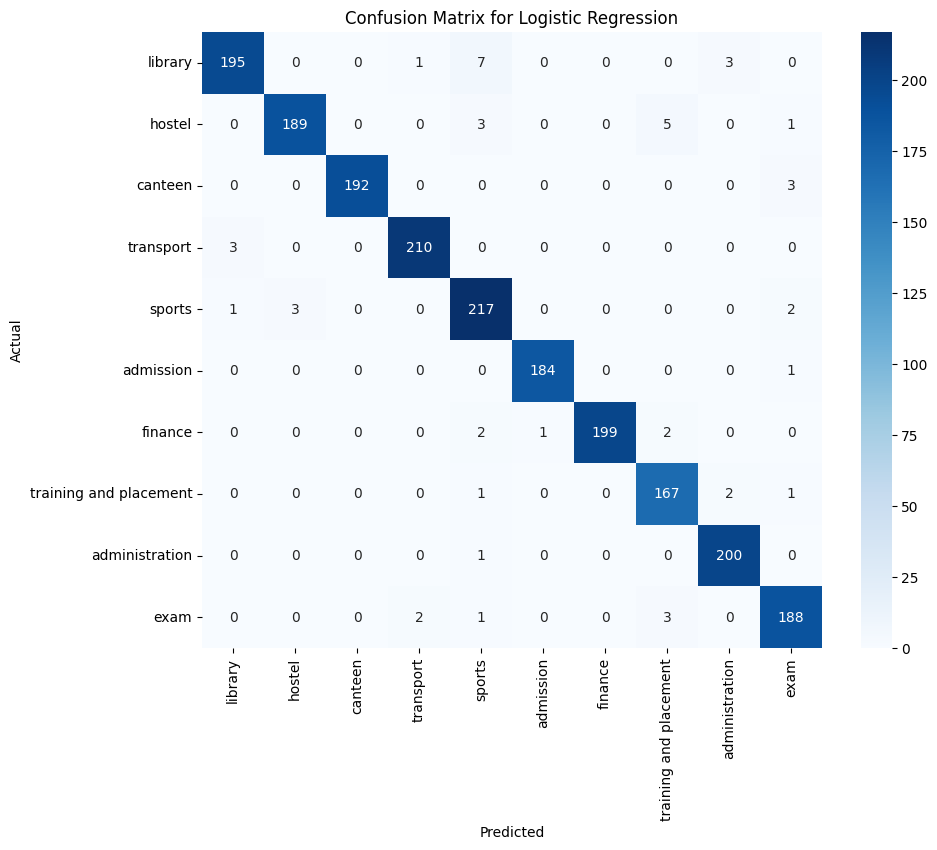

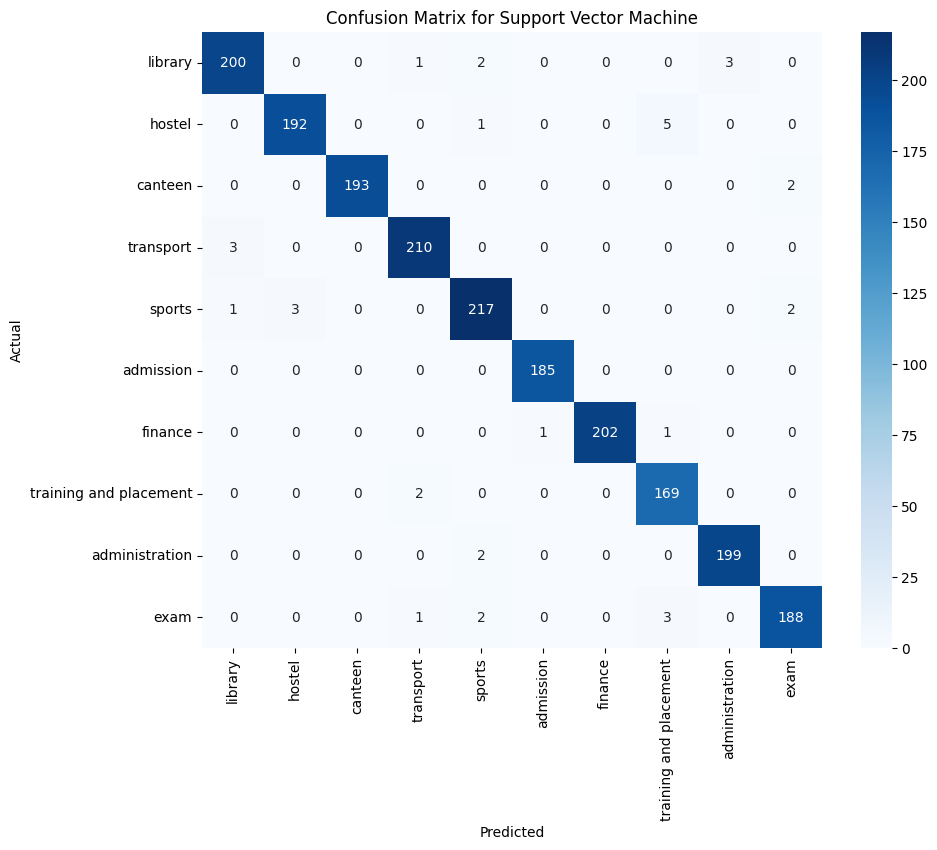

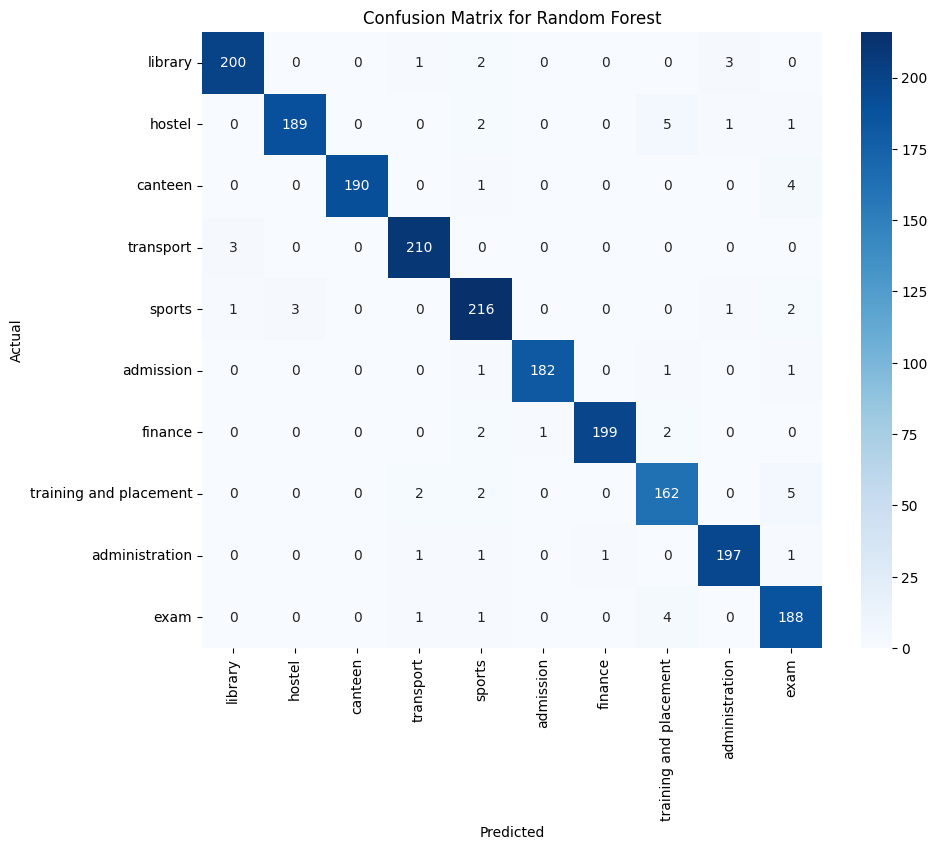

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=y.unique(), yticklabels=y.unique())
    plt.title(title)
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

logistic_y_pred = models["Logistic Regression"].predict(X_test_tfidf)
plot_confusion_matrix(y_test, logistic_y_pred, "Confusion Matrix for Logistic Regression")

svm_y_pred = models["Support Vector Machine"].predict(X_test_tfidf)
plot_confusion_matrix(y_test, svm_y_pred, "Confusion Matrix for Support Vector Machine")

random_forest_y_pred = models["Random Forest"].predict(X_test_tfidf)
plot_confusion_matrix(y_test, random_forest_y_pred, "Confusion Matrix for Random Forest")

In [11]:
y_pred = model.predict(X_test_tfidf)
y_pred

array(['training and placement', 'library', 'hostel', ..., 'admission',
       'finance', 'library'], dtype=object)

In [ ]:
import pickle
import numpy as np

with open('tfidf_model_llm.pkl', 'rb') as file:
    best_model, tfidf_vectorizer = pickle.load(file)

input_text = ["The canteen staff is slow in serving food, causing long waits."]

X_input_tfidf = tfidf_vectorizer.transform(input_text)

prediction = best_model.predict(X_input_tfidf)

print(f"Predicted Class: {prediction[0]}")

Predicted Class: canteen


In [ ]:
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

def plot_classification_metrics(y_true, y_pred, model_name):
    report = classification_report(y_true, y_pred, output_dict=True)
    
    class_metrics = {label: scores for label, scores in report.items() if label in y.unique()}

    labels = list(class_metrics.keys())
    precision = [class_metrics[label]['precision'] for label in labels]
    recall = [class_metrics[label]['recall'] for label in labels]
    f1 = [class_metrics[label]['f1-score'] for label in labels]

    x = np.arange(len(labels))
    width = 0.25

    plt.figure(figsize=(14, 6))
    plt.bar(x - width, precision, width=width, label='Precision')
    plt.bar(x, recall, width=width, label='Recall')
    plt.bar(x + width, f1, width=width, label='F1-score')

    plt.xlabel('Complaint Categories')
    plt.ylabel('Scores')
    plt.title(f'{model_name} - Precision, Recall, and F1-score per Class')
    plt.xticks(ticks=x, labels=labels, rotation=45, ha='right')
    plt.ylim(0, 1.1)
    plt.legend()
    plt.tight_layout()
    plt.show()


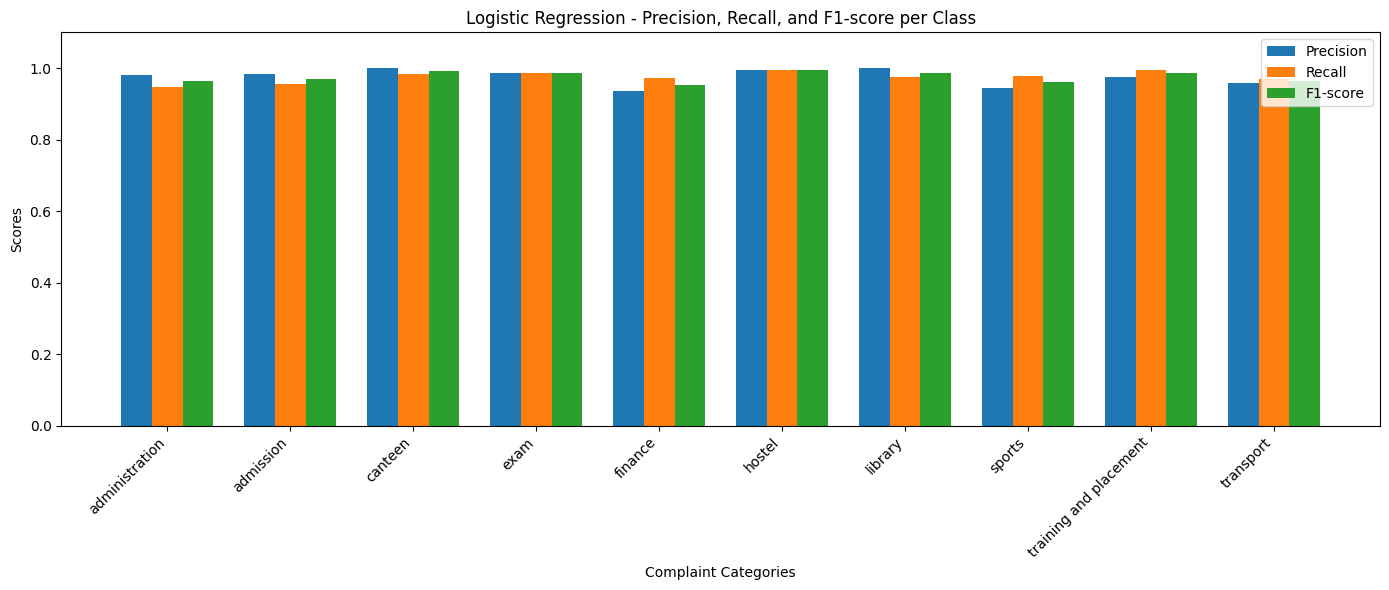

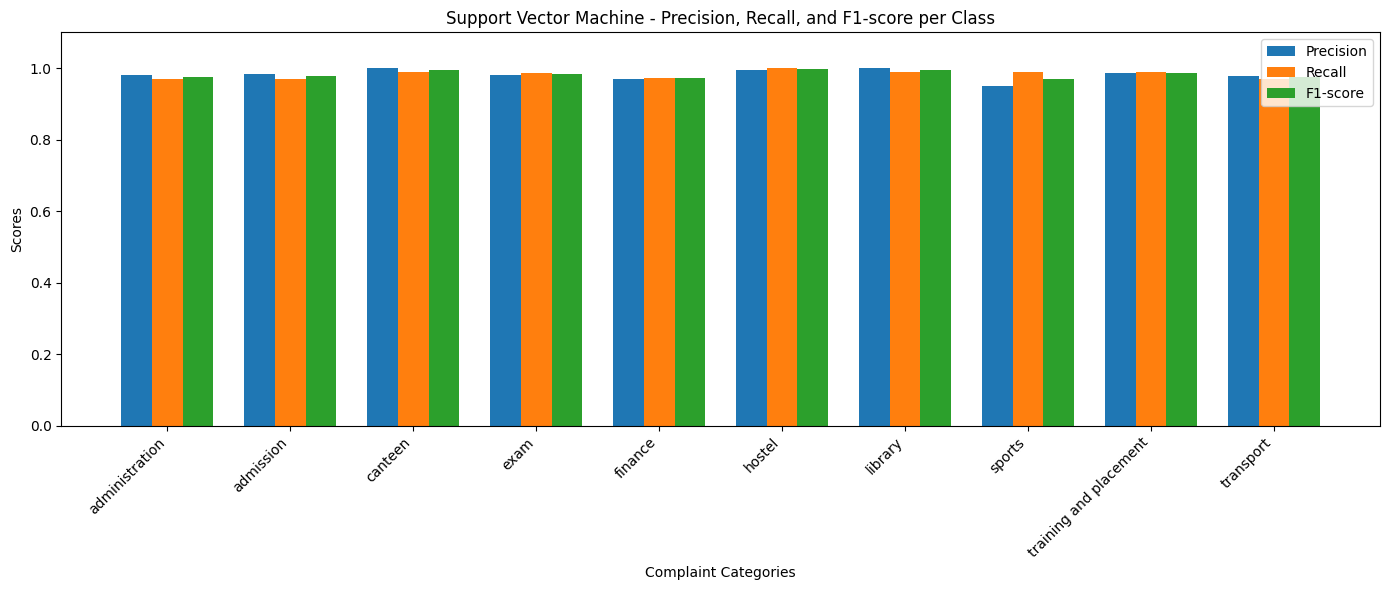

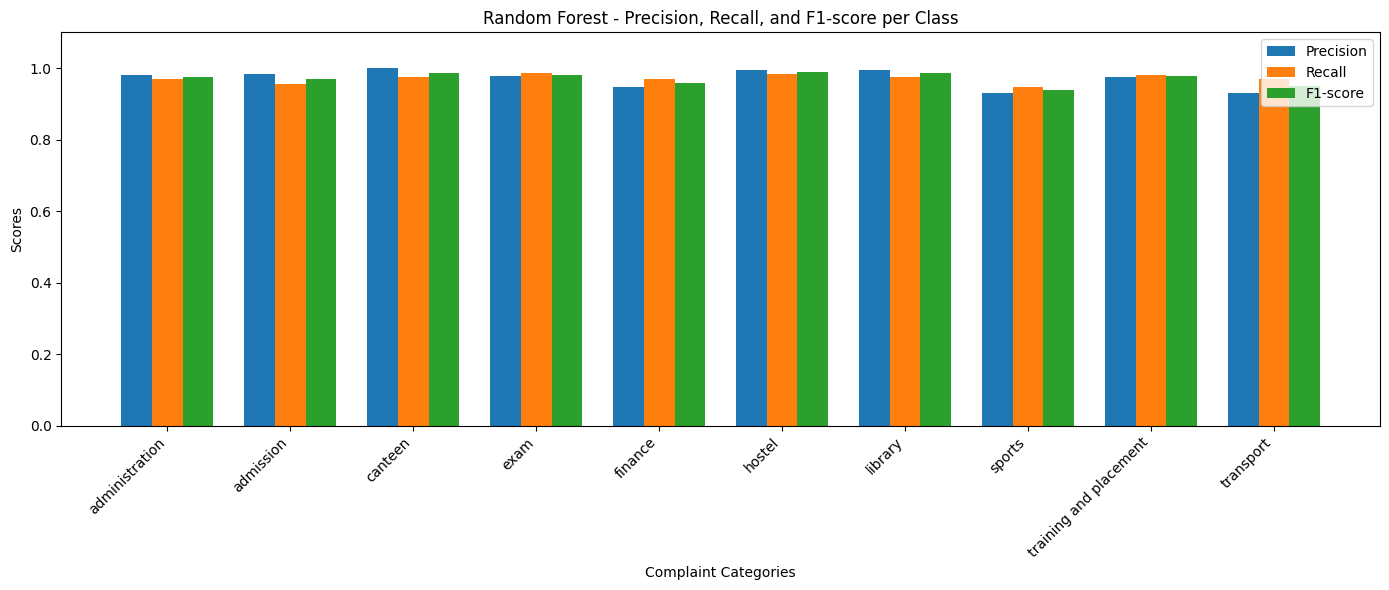

In [ ]:
logistic_y_pred = models["Logistic Regression"].predict(X_test_tfidf)
plot_classification_metrics(y_test, logistic_y_pred, "Logistic Regression")

svm_y_pred = models["Support Vector Machine"].predict(X_test_tfidf)
plot_classification_metrics(y_test, svm_y_pred, "Support Vector Machine")

random_forest_y_pred = models["Random Forest"].predict(X_test_tfidf)
plot_classification_metrics(y_test, random_forest_y_pred, "Random Forest")
